In [1]:
import h5py, os, cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# define variables 
fileDirectory = 'C:\\Users\\Admin\\UniBE\\data\\220525_530_19_1b_DRC470_02' # 150525_530_15_1a_DRC470_02
fileName = '220525_530_19_1b_DRC470_02_2.bxr' # '150525_530_15_1a_DRC470_02.bxr'
wellID = 'Well_A1' # identifier of chip well to be analysed 
chIdx = 95

# open the BXR file 
file = h5py.File(os.path.join(fileDirectory,fileName), 'r')

In [3]:
# collect experiment information 
minDigitalValue = file.attrs['MinDigitalValue'] 
maxDigitalValue = file.attrs['MaxDigitalValue'] 
minAnalogValue = file.attrs['MinAnalogValue'] 
maxAnalogValue = file.attrs['MaxAnalogValue'] 
dacFactor = (maxAnalogValue - minAnalogValue) / (maxDigitalValue - minDigitalValue) 
offsetValue = minAnalogValue - dacFactor * minDigitalValue 
samplingRate = file.attrs['SamplingRate']
chIdxs = np.array(file[wellID + '/StoredChIdxs']) 

In [4]:
# collect the required spike data 
spikeDataTimestamps = file[wellID + '/SpikeTimes'][:] 
spikeDataChIdxs = file[wellID + '/SpikeChIdxs'][:]

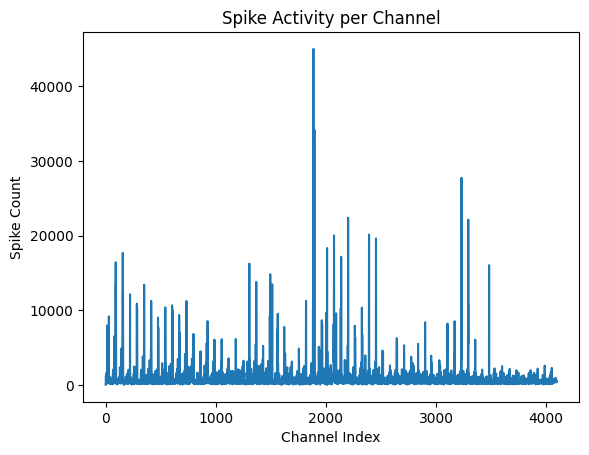

In [5]:
# Count spikes per channel
unique_channels, spike_counts = np.unique(spikeDataChIdxs, return_counts=True)
# Plot
plt.plot(unique_channels, spike_counts)
plt.xlabel('Channel Index')
plt.ylabel('Spike Count')
plt.title('Spike Activity per Channel')
plt.show()

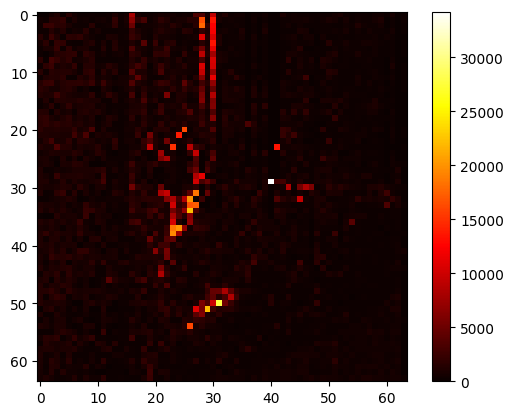

In [6]:
from collections import Counter
counts = dict(Counter(spikeDataChIdxs))

counts_array = np.zeros((64, 64))

for key in counts.keys():
    r, c = key//64, key%64
    if counts[key] > 40000:
        counts_array[r][c] = 0
    else:
        counts_array[r][c] = counts[key]

dpi = 17.5

fig = plt.Figure(figsize=(64/dpi,64/dpi), dpi=dpi)
plt.imshow(counts_array, cmap='hot', interpolation='none')
plt.axis('off')
plt.savefig(os.path.join(fileDirectory, "heatmap.png"), bbox_inches='tight', pad_inches=0, dpi=dpi)

plt.axis('on')
plt.colorbar()
plt.show()

In [7]:
%matplotlib Tk
img = plt.imread("C:\\Users\\Admin\\UniBE\\data\\220525_530_19_1b_DRC470_02\\images\\image3.jpeg")
plt.imshow(img)
points = plt.ginput(4)  # Click 4 points on the image
print(points)
plt.close()

[(np.float64(116.34848484848482), np.float64(228.92424242424238)), (np.float64(668.590909090909), np.float64(224.86363636363637)), (np.float64(688.8939393939393), np.float64(791.3181818181818)), (np.float64(96.04545454545456), np.float64(799.439393939394))]


In [8]:
heatmap = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\220525_530_19_1b_DRC470_02\\heatmap.png") 
# plt.imread --> 4-channel images (R, G, B, alpha) so use cv2.imread instead for 3-channel images

In [9]:
# Points on the heatmap
src_pts = np.array([
    [0, 0],      # top-left of heatmap
    [63, 0],     # top-right
    [63, 63],    # bottom-rigt
    [0, 63]      # bottom-left
], dtype=np.float32)

# Corresponding points on the zoomed-out image
dst_pts = np.array(points, dtype=np.float32)

# Transform
matrix = cv2.getPerspectiveTransform(src_pts, dst_pts)

# wrap heatmap to image shape
height, width, _ = img.shape
wrapped_heatmap = cv2.warpPerspective(heatmap, matrix, (width, height))

# Normalise and colour heatmap
heatmap_norm = cv2.normalize(wrapped_heatmap, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
heatmap_colour = cv2.applyColorMap(heatmap_norm, cv2.COLORMAP_JET)

# Overlay
alpha = 0.5
overlay = cv2.addWeighted(img, 1-alpha, heatmap_colour, alpha, 0)

# Display
cv2.imshow("Overlay", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
cv2.waitKey(0)
cv2.destroyAllWindows()

In [10]:
# Contour detection
img_copy = img.copy()
gray = cv2.cvtColor(img_copy, cv2.COLOR_BGR2GRAY)

_, thresholded = cv2.threshold(gray, 25, 255, cv2.THRESH_BINARY_INV)

cv2.imshow("Thresholded", thresholded)
cv2.waitKey(0)  # Wait for any key press to close the window
cv2.destroyAllWindows()
    
# rectangular kernel (5x5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))    # General kernel size
cleaned = cv2.morphologyEx(thresholded, cv2.MORPH_OPEN, kernel)  # Remove noise
closed = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)      # Fill gaps

# Find contours
inverted = cv2.bitwise_not(thresholded)
contours, _ = cv2.findContours(inverted, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

for contour in contours:
    area = cv2.contourArea(contour)   
    if area > 10000:
        print(area)
        best_contour = contour

cv2.drawContours(overlay, best_contour, -1, (0, 255, 0), 2)
cv2.imshow("Contours", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
cv2.waitKey(0)
cv2.destroyAllWindows()

for point in best_contour:
        x, y = point[0]  # point is [[x, y]]
        print(f"({x}, {y})")


106936.5
(403, 235)
(402, 236)
(403, 237)
(403, 238)
(403, 239)
(402, 240)
(402, 241)
(401, 242)
(400, 243)
(399, 243)
(398, 244)
(397, 245)
(396, 245)
(395, 245)
(394, 246)
(394, 247)
(393, 248)
(393, 249)
(393, 250)
(392, 251)
(391, 252)
(390, 253)
(389, 253)
(388, 254)
(387, 254)
(386, 255)
(385, 255)
(384, 255)
(383, 254)
(382, 253)
(382, 252)
(383, 251)
(383, 250)
(384, 249)
(385, 249)
(386, 248)
(387, 249)
(388, 248)
(387, 248)
(386, 248)
(385, 247)
(386, 246)
(387, 246)
(387, 245)
(388, 244)
(389, 243)
(389, 242)
(389, 241)
(388, 241)
(387, 240)
(387, 241)
(387, 242)
(386, 243)
(385, 244)
(384, 244)
(383, 244)
(382, 243)
(381, 242)
(380, 241)
(380, 240)
(379, 240)
(378, 239)
(377, 238)
(376, 238)
(376, 239)
(375, 240)
(374, 241)
(373, 240)
(372, 240)
(371, 240)
(370, 239)
(369, 239)
(368, 238)
(367, 239)
(366, 240)
(365, 241)
(364, 241)
(363, 242)
(362, 242)
(362, 243)
(363, 244)
(363, 245)
(363, 246)
(362, 247)
(362, 248)
(361, 249)
(360, 248)
(360, 247)
(359, 246)
(358, 246)
(

In [11]:
# Map image coordinates to 64x64 scale
matrix_inv = np.linalg.inv(matrix) # get inverse transformation matrix

# Transform
matrix_inv = cv2.getPerspectiveTransform(dst_pts, src_pts)

contour = best_contour.astype('float32') # Ensure type is float32
transformed_contour = cv2.perspectiveTransform(contour, matrix_inv)
cv2.drawContours(heatmap, [transformed_contour.astype(int)], 0, (0, 255, 0), thickness=cv2.FILLED)
cv2.imwrite('image1.png', heatmap)
cv2.destroyAllWindows()

In [12]:
mask = np.all(heatmap == [0, 255, 0], axis=-1)  
coords = np.column_stack(np.where(mask))
cleaned_heatmap = np.zeros((64, 64))
channels = []
for point in coords:
    x, y = point
    cleaned_heatmap[x][y] = counts_array[x][y]
    channels.append(64*x+y)
    print(x, y, channels[-1])
    # coordinate conventions differ between image and heatmaps (i.e., x and y are flipped)

fig = plt.Figure()
plt.imshow(cleaned_heatmap, cmap='hot', interpolation='bilinear')
plt.axis('on')
plt.colorbar()
plt.show()

0 32 32
1 27 91
1 28 92
1 29 93
1 30 94
1 31 95
1 32 96
1 33 97
1 34 98
2 27 155
2 28 156
2 29 157
2 30 158
2 31 159
2 32 160
2 33 161
2 34 162
2 37 165
3 27 219
3 28 220
3 29 221
3 30 222
3 31 223
3 32 224
3 33 225
3 34 226
3 35 227
3 36 228
3 37 229
3 38 230
4 27 283
4 28 284
4 29 285
4 30 286
4 31 287
4 32 288
4 33 289
4 34 290
4 35 291
4 36 292
4 37 293
4 38 294
4 39 295
5 27 347
5 28 348
5 29 349
5 30 350
5 31 351
5 32 352
5 33 353
5 34 354
5 35 355
5 36 356
5 37 357
5 38 358
5 39 359
5 40 360
6 26 410
6 27 411
6 28 412
6 29 413
6 30 414
6 31 415
6 32 416
6 33 417
6 34 418
6 35 419
6 36 420
6 37 421
6 38 422
6 39 423
6 40 424
7 21 469
7 22 470
7 23 471
7 26 474
7 27 475
7 28 476
7 29 477
7 30 478
7 31 479
7 32 480
7 33 481
7 34 482
7 35 483
7 36 484
7 37 485
7 38 486
7 39 487
7 40 488
7 41 489
7 42 490
8 21 533
8 22 534
8 23 535
8 24 536
8 25 537
8 26 538
8 27 539
8 28 540
8 29 541
8 30 542
8 31 543
8 32 544
8 33 545
8 34 546
8 35 547
8 36 548
8 37 549
8 38 550
8 39 551
8 40 552
8

In [13]:
# for i in range(len(spikeDataChIdxs)):
#     if spikeDataChIdxs[i] not in channels:
#         spikeDataChIdxs[i] = 0

# spikeDataChIdxs

Spike sorting

In [14]:
waveformLength = file[wellID + '/SpikeForms'].attrs['Wavelength'] 
print(waveformLength)
spikeDataWaveforms = file[wellID + '/SpikeForms'][:] 

31


In [15]:
waveformData = [] 
for idx, ch in enumerate(channels): 
    if ch == chIdx: 
        waveformData.append(spikeDataWaveforms[idx*waveformLength:idx*waveformLength+waveformLength]) 

In [16]:
x = np.arange(0, waveformLength, 1) / samplingRate 
for waveform in waveformData: 
    # convert the waveform to analog 
    y = offsetValue + dacFactor * waveform
    fig = plt.figure()
    plt.plot(x, y, color='blue', alpha=0.3)
    plt.show()

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
pcs = pca.fit_transform(waveformData)

ValueError: n_components=3 must be between 0 and min(n_samples, n_features)=1 with svd_solver='full'

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(pcs[:, 0], pcs[:, 1], s=1)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title(f'PCA of Spike Waveforms - Channel {chIdx} ')
plt.show()